# Belib' Forecast - First exploratory analysis

**Data:** Belib' charging-point statuses collected every 5 minutes from the Paris open-data API, from Wed 25 Nov 2026 (evening) to Sat 28 Nov 2026 (midday), about 2.5 days.

**Questions:**
1. How much of the raw data is noise?
2. How long do charging sessions last?
3. How does occupancy change during the day?
4. How many points are broken?

All times are in Paris time.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter


## 1. Load the data

Events (one row per status change), point locations and the collector's run log are loaded from the `data` branch. Times are stored in UTC and converted to Paris time, because charging behaviour follows local time.

In [2]:
DATA = Path.home() / "projects" / "belib-data"
TZ = "Europe/Paris"
IMG_DIR = Path("../docs/img")
IMG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
NAVY, RED, GREY = "#1e3a5f", "#c0392b", "#94a3b8"

In [3]:
events = pd.concat(
    [pd.read_csv(f) for f in sorted((DATA / "events").glob("*.csv"))],
    ignore_index=True,
)
points = pd.read_csv(DATA / "points.csv")
runs = pd.read_csv(DATA / "runs.csv")

# Times are stored in UTC; convert to Paris time for analysis
events["t"] = pd.to_datetime(events["last_updated"], utc=True).dt.tz_convert(TZ)
runs["run_at"] = pd.to_datetime(runs["run_at"], utc=True).dt.tz_convert(TZ)

print(f"{len(events):,} events, {events['id_pdc'].nunique():,} points")
print(f"from {events['t'].min()} to {events['t'].max()}")
events.head()

45,198 events, 2,104 points
from 2026-06-08 07:25:57+02:00 to 2026-11-28 16:04:58+01:00


,id_pdc,statut,last_updated,first_seen_at,t
0,FR*V75*E9006*02*2,Inconnu,2026-10-09T02:30:10+00:00,2026-11-25T17:20:59+00:00,2026-10-09 04:30:10+02:00
1,FR*V75*EPX01*02*1,Disponible,2026-11-19T11:39:11+00:00,2026-11-25T17:20:59+00:00,2026-11-19 12:39:11+01:00
2,FR*V75*EPX18*17*2,Disponible,2026-11-25T03:30:10+00:00,2026-11-25T17:20:59+00:00,2026-11-25 04:30:10+01:00
3,FR*V75*EHBSAE*PDA*01*3,Disponible,2026-11-25T03:30:10+00:00,2026-11-25T17:20:59+00:00,2026-11-25 04:30:10+01:00
4,FR*V75*EPX07*15*3,Occupé (en charge),2026-11-25T03:30:10+00:00,2026-11-25T17:20:59+00:00,2026-11-25 04:30:10+01:00


**Note:** the earliest event times go back months before the collection started. The first event of each point is its `last_updated` at collection start, which can be very old for broken points. Any time-based analysis must therefore start at the first collector run, not at the first event.

## 2. Clean the data

Two cleaning steps:
- **Keep only points with a location.** About 87 points have no address or coordinates; they are probably planned chargers that don't exist yet.
- **Remove events where the status didn't change.** The source sometimes refreshes `last_updated` without a real change, for example a nightly mass update around 04:35. For each point, an event is kept only if its status differs from the previous one (`groupby` + `shift`, the pandas equivalent of SQL's `LAG`).

In [4]:
# Keep only points that really exist on the map
located = points.dropna(subset=["lat", "lon"])["id_pdc"]
ev = events[events["id_pdc"].isin(located)].copy()

# Remove events where the status didn't change (e.g. the nightly mass update)
ev = ev.sort_values(["id_pdc", "t"])
ev["prev_statut"] = ev.groupby("id_pdc")["statut"].shift(1)
fake = ev["prev_statut"].notna() & (ev["statut"] == ev["prev_statut"])

print(f"Removed {fake.sum():,} same-status events out of {len(ev):,} "
      f"({fake.mean():.0%})")
ev = ev[~fake].copy()

Removed 9,419 same-status events out of 44,862 (21%)


**Result:** 9,114 same-status events removed out of 41,612 (22%).

Without this step, each fake event would look like the start of a new charging session and would distort durations and activity counts.
About 22% of raw events are noise (same status, new timestamp) and must be removed.

In [5]:
ev["next_t"] = ev.groupby("id_pdc")["t"].shift(-1)
ev["is_first"] = ev.groupby("id_pdc").cumcount() == 0

sessions = ev[
    (ev["statut"] == "Occupé (en charge)")
    & ~ev["is_first"]
    & ev["next_t"].notna()
].copy()
sessions["duration_min"] = (sessions["next_t"] - sessions["t"]).dt.total_seconds() / 60

print(f"{len(sessions):,} complete sessions")
print(sessions["duration_min"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1))

15,167 complete sessions
count    15167.0
mean       229.5
std        243.7
min          0.0
10%         23.6
25%         64.1
50%        141.1
75%        298.3
90%        603.4
max       2535.5
Name: duration_min, dtype: float64


## 3. How long do charging sessions last?

A session starts with an "Occupé (en charge)" event and ends at the next event of the same point.

Two kinds of sessions are excluded because their duration is unknown (censored data):
- sessions already running when the collector started (start unknown),
- sessions still running now (end unknown).

Sessions shorter than 2 minutes are treated as glitches or failed attempts and removed from the chart.

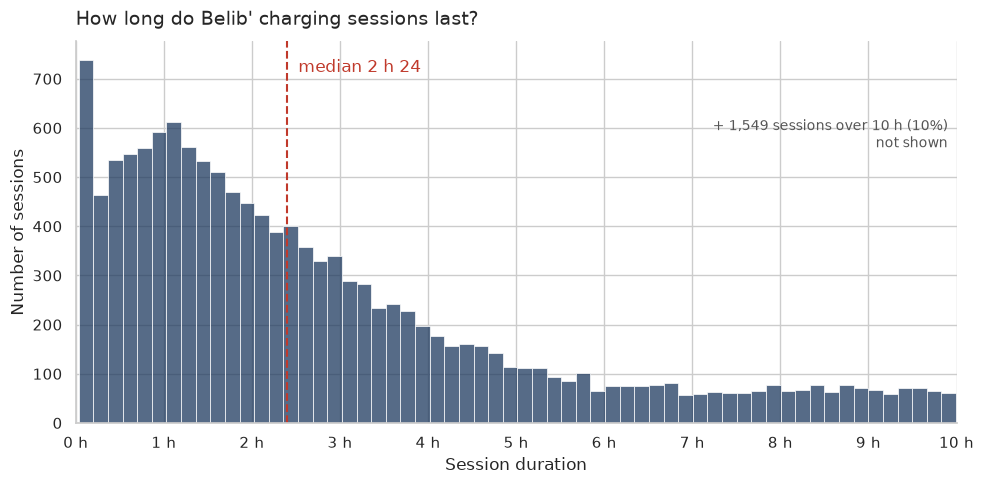

In [6]:
sns.set_theme(style="whitegrid", context="notebook")

d = sessions["duration_min"]
d = d[d >= 2]                      # drop sub-2-minute "sessions" (glitches)
long = d > 600
median = d.median()

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(d[~long], bins=60, color=NAVY, edgecolor="white", linewidth=0.5, ax=ax)

# Median line
ax.axvline(median, color=RED, linestyle="--", linewidth=1.5)
ax.text(median + 8, ax.get_ylim()[1] * 0.92,
        f"median {median // 60:.0f} h {median % 60:02.0f}", color=RED)

# Axis in hours
ax.set_xticks(range(0, 601, 60))
ax.set_xticklabels([f"{m // 60} h" for m in range(0, 601, 60)])
ax.set_xlim(0, 600)

ax.set_title("How long do Belib' charging sessions last?", loc="left", fontsize=14, pad=12)
ax.set_xlabel("Session duration")
ax.set_ylabel("Number of sessions")

# Note for the sessions not shown
ax.text(0.99, 0.80,
        f"+ {long.sum():,} sessions over 10 h ({long.mean():.0%})\nnot shown",
        transform=ax.transAxes, ha="right", va="top", color="#555555", fontsize=10)

sns.despine()
plt.tight_layout()

# Save for the README / blog
img_dir = Path("../docs/img")
img_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(img_dir / "session_durations.png", dpi=150)
plt.show()

**Result:** 13,772 complete sessions.

| Statistic | Duration |
|---|---|
| 10% shorter than | 24 min |
| 25% shorter than | 1 h 05 |
| **Median** | **2 h 26** |
| 25% longer than | 5 h 16 |
| 10% longer than | 10 h 12 |
| Longest | ~42 h |

**Observations:**
- **Three groups:** very short sessions (under 10 min, probably failed attempts or glitches), normal charges (30 min to 3 h, peaking around 1 h), and very long stays (over 10 h, about 11%, probably cars left overnight).
- **The mean (3 h 55) is much higher than the median (2 h 26)** because of the long stays; the median is the better "typical" value.
- **Some sessions last 0 minutes** and one lasts ~42 h: to investigate (data glitches, or a point stuck on "Occupé").

**For the model:** the time a car has already been charging is likely a strong feature. A car charging for 1 h will probably leave soon; one still there after 6 h probably won't leave before morning.

## 4. How does occupancy change during the day?

Events only record changes. To know the state of every point at a given moment, the status of each point is rebuilt every 15 minutes with `merge_asof`, which takes the last event before each moment.

Occupancy = share of **working** points (available or charging) that are occupied. Points in maintenance or with an unknown status are left out, since they are neither free nor occupied.

In [7]:
# State of every point every 15 minutes, from the first to the last collector run
start = runs["run_at"].min().ceil("15min")
end = runs["run_at"].max().floor("15min")
times = pd.date_range(start, end, freq="15min")

grid = pd.MultiIndex.from_product(
    [ev["id_pdc"].unique(), times], names=["id_pdc", "time"]
).to_frame(index=False)

state = pd.merge_asof(
    grid.sort_values("time"),
    ev[["id_pdc", "t", "statut"]].sort_values("t"),
    left_on="time", right_on="t", by="id_pdc", direction="backward",
)

# Occupancy = share of working points that are occupied
working = state[state["statut"].isin(["Disponible", "Occupé (en charge)"])]
occupancy = (
    working.assign(occupied=working["statut"] == "Occupé (en charge)")
    .groupby("time")["occupied"].mean()
)

print(f"{len(times)} moments, from {start:%a %d %b %H:%M} to {end:%a %d %b %H:%M}")

279 moments, from Wed 25 Nov 18:30 to Sat 28 Nov 16:00


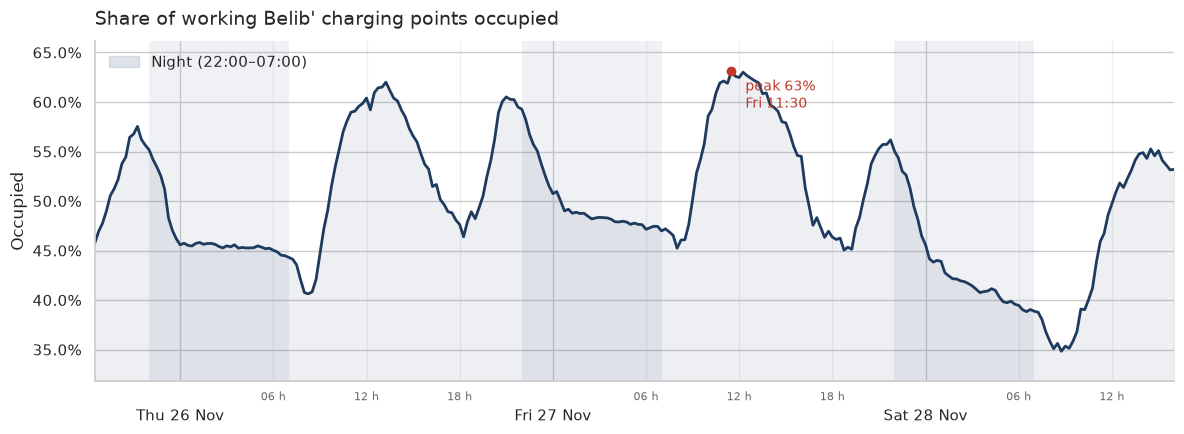

In [8]:
sns.set_theme(style="whitegrid", context="notebook")
tz = occupancy.index.tz

fig, ax = plt.subplots(figsize=(12, 4.5))

# Shade nights (22:00 → 07:00)
first_day = occupancy.index.min().normalize() - pd.Timedelta(days=1)
for day in pd.date_range(first_day, occupancy.index.max().normalize(), freq="D"):
    ax.axvspan(day + pd.Timedelta(hours=22), day + pd.Timedelta(hours=31),
               color=GREY, alpha=0.15, linewidth=0)

# Occupancy line + light fill underneath
ax.plot(occupancy.index, occupancy.values, color=NAVY, linewidth=2)
ax.fill_between(occupancy.index, occupancy.values, occupancy.min() - 0.03,
                color=NAVY, alpha=0.08)

# Mark the highest point
peak_time, peak_value = occupancy.idxmax(), occupancy.max()
ax.scatter([peak_time], [peak_value], color=RED, zorder=3)
ax.annotate(f"peak {peak_value:.0%}\n{peak_time:%a %H:%M}",
            xy=(peak_time, peak_value), xytext=(10, -5),
            textcoords="offset points", color=RED, fontsize=10, va="top")

# Axes
ax.set_xlim(occupancy.index.min(), occupancy.index.max())
ax.set_ylim(occupancy.min() - 0.03, occupancy.max() + 0.03)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.xaxis.set_major_locator(mdates.DayLocator(tz=tz))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b", tz=tz))
ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18], tz=tz))
ax.xaxis.set_minor_formatter(mdates.DateFormatter("%H h", tz=tz))
ax.tick_params(axis="x", which="major", pad=14)
ax.tick_params(axis="x", which="minor", labelsize=8, colors="#666666")
ax.grid(which="minor", axis="x", alpha=0.3)

ax.set_title("Share of working Belib' charging points occupied",
             loc="left", fontsize=14, pad=12)
ax.set_xlabel("")
ax.set_ylabel("Occupied")
ax.legend(handles=[Patch(color=GREY, alpha=0.3, label="Night (22:00–07:00)")],
          loc="upper left", frameon=False)

sns.despine()
plt.tight_layout()

img_dir = Path("../docs/img")
img_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(img_dir / "occupancy_over_time.png", dpi=150)
plt.show()

**Result:** a clear daily cycle, repeated every day.

| Time (Paris) | Occupancy | Interpretation |
|---|---|---|
| 00:00 – 07:00 | flat, ~45–48% | Cars charging overnight; nobody moves |
| ~08:00 | **lowest** (41–45%) | Overnight cars leave before new drivers arrive |
| 12:00 – 13:00 | **highest** (60–63%) | Daytime: work, shopping, appointments |
| ~17:00 – 18:00 | dip (~45–47%) | Daytime drivers leave |
| 20:00 – 21:00 | second peak (56–60%) | Residents come home and plug in |

**Observations:**
- **The lowest point is 8:00, not the middle of the night**, because overnight cars keep points busy until morning. This matches the group of sessions longer than 10 h.
- **Saturday morning is lower** (~35% at 9:00) than weekday mornings. Only one weekend morning so far: to confirm with more data.
- **Occupancy never drops below ~35%:** a third or more of the working points are always occupied.

**For the model:** hour of day is a key feature, with **two daily peaks**. Day of week (or weekday vs weekend) probably matters too.

## 5. How many points are broken?

For each point, the share of 15-minute moments where its status was neither "Disponible" nor "Occupé (en charge)" (for example "En maintenance" or "Inconnu").

In [9]:
broken_share = (
    state.assign(broken=~state["statut"].isin(["Disponible", "Occupé (en charge)"]))
    .groupby("id_pdc")["broken"].mean()
)

print(f"Points broken the whole time: {(broken_share == 1).sum()}")
print(f"Points broken more than half the time: {(broken_share > 0.5).sum()}")
print(f"Points never broken: {(broken_share == 0).sum()}")

Points broken the whole time: 50
Points broken more than half the time: 66
Points never broken: 1677


**Result:** out of about 2,017 points with a location:

| Category | Points |
|---|---|
| Never broken | 1,690 (~84%) |
| Broken some of the time, less than half | ~260 |
| Broken more than half the time | 66 |
| Broken the whole time | 50 |

**Observations:**
- Most of the network works reliably.
- The 50 always-broken points match the 50 points "En maintenance" seen on the first day.
- 16 points are broken often but not always: worth watching.

**For the model:** points broken the whole time never change and will be excluded from training. A point's recent reliability could be a useful feature.

## 6. Occupancy by day of week and hour

Average share of working points occupied, for each day of the week and each hour (Paris time). Each cell averages the 15-minute snapshots of that hour on that day.

In [10]:
working = state[state["statut"].isin(["Disponible", "Occupé (en charge)"])].copy()
working["occupied"] = working["statut"] == "Occupé (en charge)"
local_time = working["time"].dt.tz_convert(TZ)
working["day"] = local_time.dt.day_name().str[:3]      # Mon, Tue, ...
working["hour"] = local_time.dt.hour

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

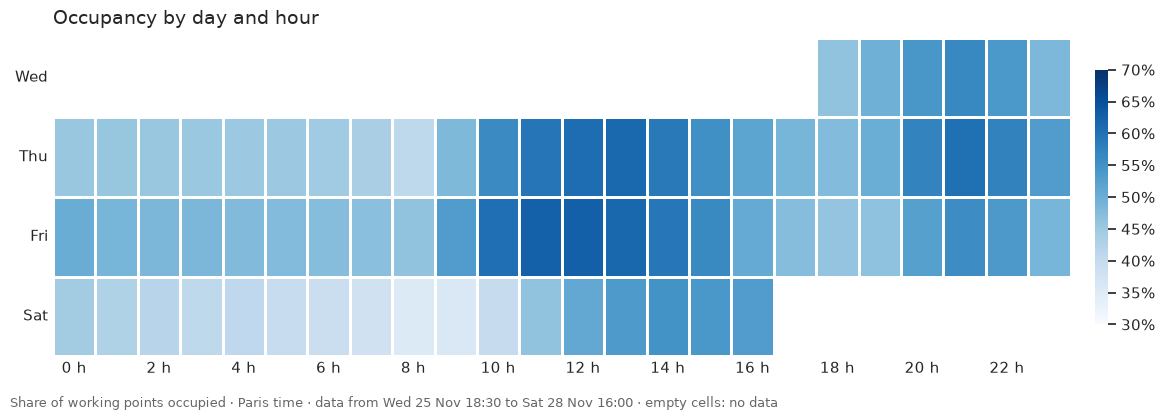

In [11]:
heat = working.pivot_table(index="day", columns="hour", values="occupied", aggfunc="mean")
heat = heat.reindex([d for d in days if d in heat.index])

period_start = local_time.min()
period_end = local_time.max()

fig, ax = plt.subplots(figsize=(13, 4.2))
sns.heatmap(
    heat, cmap="Blues", vmin=0.3, vmax=0.7,
    linewidths=1, linecolor="white",
    cbar_kws={"format": PercentFormatter(1.0, decimals=0), "shrink": 0.8, "pad": 0.02},
    ax=ax,
)
ax.grid(False)                                   # empty cells stay plain white
ax.set_xticks([h + 0.5 for h in range(0, 24, 2)])
ax.set_xticklabels([f"{h} h" for h in range(0, 24, 2)], rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.tick_params(length=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Occupancy by day and hour", loc="left", fontsize=14, pad=10)
fig.text(
    0.01, 0.01,
    f"Share of working points occupied · Paris time · "
    f"data from {period_start:%a %d %b %H:%M} to {period_end:%a %d %b %H:%M} · "
    f"empty cells: no data",
    fontsize=9, color="#666666",
)
plt.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(IMG_DIR / "occupancy_heatmap.png", dpi=150)
plt.show()

**Result:** the weekday rhythm is consistent across days.

| Time (Paris) | Weekdays (Thu, Fri) | Saturday |
|---|---|---|
| 0 h – 7 h | about 45–50%, stable | about 35–45%, decreasing |
| 8 h | daily low (about 40%) | lower still (about 30–35%) |
| 11 h – 13 h | main peak (up to about 68% on Friday) | rising slowly (about 50–55% by early afternoon) |
| around 17 h | dip | (no data yet) |
| 20 h – 21 h | second peak (about 60%) | (no data yet) |

**Observations:**
- **Weekdays follow a work schedule:** a low at 8 h, a midday peak, a dip around 17 h and an evening peak.
- **Saturday morning is much quieter** than weekday mornings, and occupancy rises later in the day.
- **Friday night is busier than Thursday night**, possibly people charging before the weekend.

**Limits:** each row is a single day, and Wednesday and Saturday are incomplete (white cells = no data). To be confirmed after a full week, ideally two.

**For the model:** both **hour of day** and **day of week** (or at least weekday vs weekend) are likely useful features.

## 7. Occupancy by arrondissement

Average share of working points occupied over the whole period, for each arrondissement. The number of points in each arrondissement is shown in brackets; the dashed line is the Paris average.

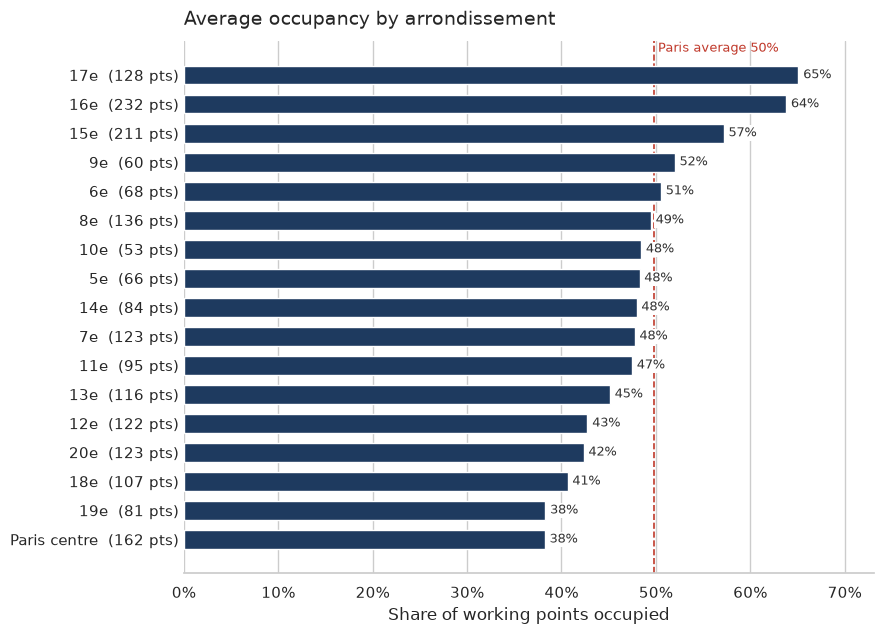

In [12]:
with_arr = working.merge(points[["id_pdc", "arrondissement"]], on="id_pdc")
by_arr = with_arr.groupby("arrondissement").agg(
    occupancy=("occupied", "mean"),
    n_points=("id_pdc", "nunique"),
).sort_values("occupancy")

def short_name(a):
    """'08e Arrondissement' -> '8e'; keep 'Paris centre' as is."""
    return a.replace(" Arrondissement", "").lstrip("0") if "Arrondissement" in a else a

labels = [f"{short_name(a)}  ({n} pts)" for a, n in zip(by_arr.index, by_arr["n_points"])]
network_avg = working["occupied"].mean()

fig, ax = plt.subplots(figsize=(9, 6.5))

# Average line first, behind everything (zorder=0)
ax.axvline(network_avg, color=RED, linestyle="--", linewidth=1.2, zorder=0)
ax.text(network_avg, len(by_arr) - 0.3, f" Paris average {network_avg:.0%}",
        color=RED, fontsize=9, va="bottom")

bars = ax.barh(labels, by_arr["occupancy"], color=NAVY, height=0.65, zorder=2)
for bar, value in zip(bars, by_arr["occupancy"]):
    ax.text(value + 0.005, bar.get_y() + bar.get_height() / 2, f"{value:.0%}",
            va="center", fontsize=9, color="#333333", zorder=3,
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})

ax.set_xlim(0, by_arr["occupancy"].max() + 0.08)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)                           # grid lines behind the bars
ax.set_title("Average occupancy by arrondissement", loc="left", fontsize=14, pad=12)
ax.set_xlabel("Share of working points occupied")
sns.despine(left=True)
plt.tight_layout()
fig.savefig(IMG_DIR / "occupancy_by_arrondissement.png", dpi=150)
plt.show()

**Result:** occupancy varies strongly with location, from 38% to 65% (Paris average: 50%).

| Group | Arrondissements | Occupancy |
|---|---|---|
| Busiest | 17e, 16e, 15e | 57–65% |
| Around the average | 9e, 6e, 8e, 10e, 5e, 14e, 7e, 11e | 47–52% |
| Least busy | 13e, 12e, 20e, 18e, 19e, Paris centre | 38–45% |

**Observations:**
- **A west/east contrast:** the western arrondissements (15e, 16e, 17e) are the busiest; the north-east (18e, 19e, 20e) and Paris centre are the least busy.
- A possible explanation is that the western, mostly residential arrondissements have more electric cars per charging point. This is a **hypothesis**: the data shows the difference, not its cause.
- Arrondissements with few points have less reliable averages; the point counts in brackets show how much data is behind each bar.

**For the model:** location matters, so the station's arrondissement, or its own historical occupancy, is a likely useful feature.